# **Análise exploratória — H&M**

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.options.display.max_columns = None
pd.options.display.float_format = "{:.3f}".format

In [2]:
DATA_DIR = Path("../data").resolve()

customer_purchase = pd.read_parquet(DATA_DIR / "customer_purchase.parquet")
transactions_features = pd.read_parquet(DATA_DIR / "transactions_features.parquet")
customer_monthly = pd.read_parquet(DATA_DIR / "customer_monthly.parquet")

# **Perguntas centrais**
1. Qual é o nível de recorrência e como ele evolui?
2. Quanto os recorrentes representam dos itens e do valor observado?
3. Quais características e coortes apresentam maior recorrência, frequência e valor?
4. Quais grupos de produtos aparecem na primeira compra observada e nas compras posteriores?
5. Como os canais se relacionam com recorrência, frequência, valor e produtos?


## 1. Qual é o nível de recorrência e como ele evolui?


In [3]:
## criar a tag de recorrente ou não baseado na observação de recorrência

customer_purchase["customer_type"] = np.where(
    customer_purchase["is_recurring_observed"],
    "Recorrente",
    "Compra única",
)

In [4]:
customer_purchase

,customer_id,first_purchase_date,second_purchase_date,last_purchase_date,purchase_days,items_purchased,value,days_to_second_purchase,recency_days,available_followup_days,is_recurring_observed,cohort_month,unique_article,channels_used,channel_profile,fn,active,club_member_status,fashion_news_frequency,age,age_group,customer_type
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,2018-12-27,2019-05-02,2020-09-05,10,21,0.649,126,18,635,True,2018-12-01,19,2,MULTICHANNEL,NaN,NaN,ACTIVE,NONE,49,45-54,Recorrente
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,2018-09-21,2018-09-25,2020-07-08,23,86,2.602,4,77,732,True,2018-09-01,64,2,MULTICHANNEL,NaN,NaN,ACTIVE,NONE,25,25-34,Recorrente
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,2018-09-20,2018-09-24,2020-09-15,7,18,0.705,4,8,733,True,2018-09-01,14,1,CHANNEL_2_ONLY,NaN,NaN,ACTIVE,NONE,24,15-24,Recorrente
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,2019-06-09,NaT,2019-06-09,1,2,0.061,<NA>,472,471,False,2019-06-01,2,1,CHANNEL_2_ONLY,NaN,NaN,ACTIVE,NONE,54,45-54,Compra única
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,2018-10-12,2019-03-07,2020-08-12,6,13,0.470,146,42,711,True,2018-10-01,12,2,MULTICHANNEL,1.000,1.000,ACTIVE,REGULARLY,52,45-54,Recorrente
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1362276,ffffbbf78b6eaac697a8a5dfbfd2bfa8113ee5b403e474...,2019-04-03,2019-04-18,2020-09-06,11,51,1.292,15,17,538,True,2019-04-01,42,2,MULTICHANNEL,NaN,NaN,ACTIVE,NONE,24,15-24,Recorrente
1362277,ffffcd5046a6143d29a04fb8c424ce494a76e5cdf4fab5...,2018-09-25,2018-11-20,2020-08-18,19,84,1.807,56,36,728,True,2018-09-01,79,2,MULTICHANNEL,NaN,NaN,ACTIVE,NONE,21,15-24,Recorrente
1362278,ffffcf35913a0bee60e8741cb2b4e78b8a98ee5ff2e6a1...,2018-09-20,2018-10-18,2020-09-09,19,45,0.789,28,14,733,True,2018-09-01,40,2,MULTICHANNEL,1.000,1.000,ACTIVE,REGULARLY,21,15-24,Recorrente
1362279,ffffd7744cebcf3aca44ae7049d2a94b87074c3d4ffe38...,2020-04-05,2020-04-09,2020-06-22,4,7,0.209,4,93,170,True,2020-04-01,6,2,MULTICHANNEL,1.000,1.000,ACTIVE,REGULARLY,18,15-24,Recorrente


In [5]:
## contar os clientes recorrentes e seu percentual de participação dos clientes totais

recorrency_summary = customer_purchase.groupby("customer_type", as_index=False).size()
recorrency_summary = recorrency_summary.rename(columns={"size": "customers"})
recorrency_summary["percent"] = recorrency_summary["customers"]/recorrency_summary["customers"].sum().round(2)*100


display(recorrency_summary)

,customer_type,customers,percent
0,Compra única,447973,32.884
1,Recorrente,914308,67.116


In [6]:
## Verificar os dias distintos de compras por cliente

purchase_days_summary = customer_purchase["purchase_days"].describe(percentiles= [0.25, 0.50, 0.75, 0.90, 0.99])
pd.DataFrame(purchase_days_summary)

,purchase_days
count,1362281.000
mean,6.665
std,9.707
min,1.000
25%,1.000
50%,3.000
75%,8.000
90%,17.000
99%,45.000
max,427.000


Text(0, 0.5, 'Clientes')

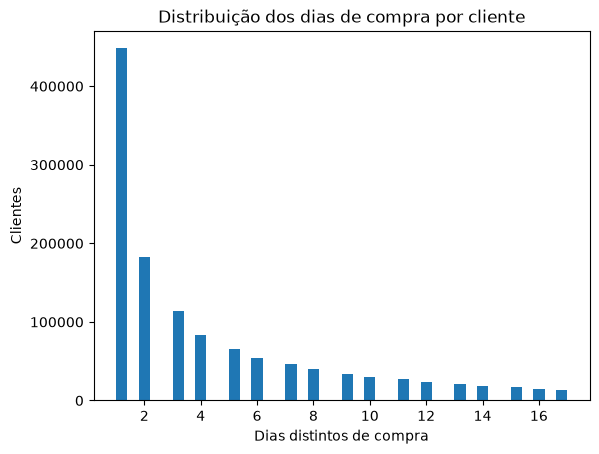

In [7]:

## Distribuição da maioria dos clientes por quantidade de dias de compra distintos para verificar a frequência da recorrência
limit = customer_purchase["purchase_days"].quantile(0.90)
fig = plt.hist(customer_purchase.loc[customer_purchase["purchase_days"] <= limit,"purchase_days"], bins=40)
plt.title("Distribuição dos dias de compra por cliente")
plt.xlabel("Dias distintos de compra")
plt.ylabel("Clientes")


In [8]:
## Em quanto ocorre a segunda compra dos clientes recorrentes

days_to_second = customer_purchase["days_to_second_purchase"].dropna()

pd.DataFrame(days_to_second.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.99]))

,days_to_second_purchase
count,914308.000
mean,90.586
std,117.091
min,1.000
25%,13.000
50%,44.000
75%,120.000
90%,247.000
99%,544.000
max,731.000


In [9]:
## Identificar a diferença entre a mediana e o IQR para verificar se há simetria no comportamento da maioria dos clientes

q1 = days_to_second.quantile(0.25)
median = days_to_second.median()
q3 = days_to_second.quantile(0.75)
iqr = q3 - q1

return_time_summary = pd.Series({
    "Q1": q1,
    "Mediana": median,
    "Q3": q3,
    "IQR": iqr,
})

return_time_summary

Q1         13.000
Mediana    44.000
Q3        120.000
IQR       107.000
dtype: float64

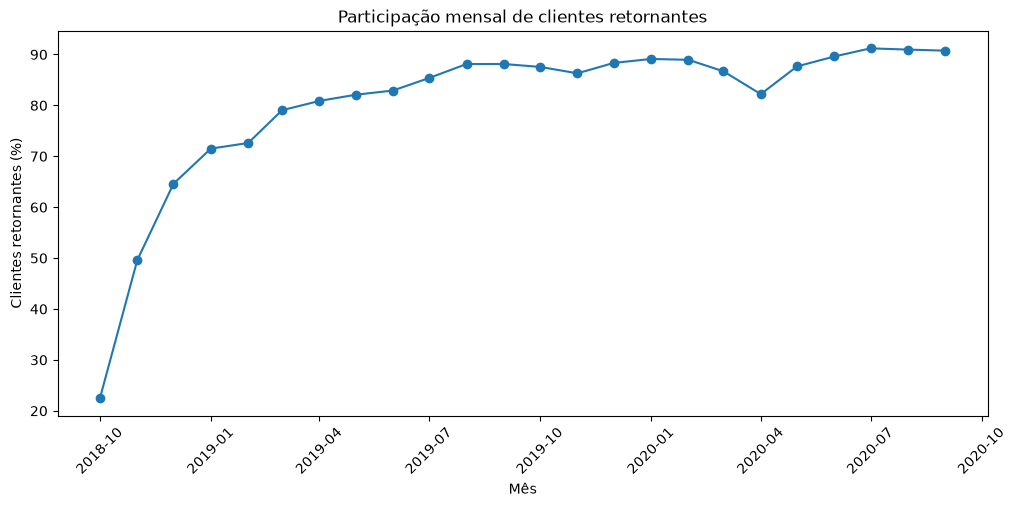

In [10]:
## Identificar a participação dos clientes recorrentes em cada coorte

customer_monthly["customer_status"] = np.where(
    customer_monthly["cohort_index"] == 0,
    "Novo",
    "Retornante",
)

monthly_customer_mix = (
    customer_monthly
    .groupby(["purchase_month", "customer_status"], as_index=False)
    .agg(customers=("customer_id", "nunique"))
)

monthly_customer_mix["percent"] = (
    monthly_customer_mix["customers"]
    / monthly_customer_mix.groupby("purchase_month")["customers"].transform("sum")
    * 100
)

returning_monthly = monthly_customer_mix[
    (monthly_customer_mix["customer_status"] == "Retornante")
]

plt.figure(figsize=(12, 5))
plt.plot(
    returning_monthly["purchase_month"],
    returning_monthly["percent"],
    marker="o",
)

plt.title("Participação mensal de clientes retornantes")
plt.xlabel("Mês")
plt.ylabel("Clientes retornantes (%)")
plt.xticks(rotation=45)
plt.show()


### Principais Insights

- Durante o período analisado, 67,1% dos clientes realizaram compras em pelo menos dois dias distintos, enquanto 32,9% compraram em apenas um dia

- A frequência apresenta distribuição assimétrica com a maioria (90% dos clientes) comprando em até 17 dias, com uma distância grande da mediana

- Entre os clientes recorrentes, metade retornou em até 44 dias, com os 50% centrais realizando a segunda compra entre 13 e 120 dias, indicando uma variação considerável no tempo de retorno

## 2. Quanto os recorrentes representam dos clientes, itens e do valor observado?


In [11]:
## verificar a participação de itens, clientes e valor para os clientes únicos e recorrentes

recurrence_impact = customer_purchase.groupby("customer_type").agg(
    customers=("customer_id", "count"),
    items = ("items_purchased", "sum"),
    value = ("value","sum")
).reset_index()

colunas = ["customers","items","value"]

for agg in colunas:
    recurrence_impact[f"percentual_{agg}"] = (recurrence_impact[agg]/recurrence_impact[agg].sum()*100)

recurrence_impact

,customer_type,customers,items,value,percentual_customers,percentual_items,percentual_value
0,Compra única,447973,1550285,42137.314,32.884,4.877,4.763
1,Recorrente,914308,30238039,842508.660,67.116,95.123,95.237


In [12]:
## Os recorrentes compram em média quantos itens e qual a média de dias de compra?

recurrence_behavior = customer_purchase.groupby("customer_type").agg(
        avg_purchase_days=("purchase_days", "mean"),
        avg_items=("items_purchased", "mean"),
        avg_value=("value", "mean"),
    ).round(2).reset_index()

recurrence_behavior

,customer_type,avg_purchase_days,avg_items,avg_value
0,Compra única,1.000,3.460,0.090
1,Recorrente,9.440,33.070,0.920


### Principais Insights
- Os clientes recorrentes são 67% da base, concentrando 95,1% dos itens comprados e 95,2% do valor observado
- Os clientes recorrentes compraram, em média, 33 itens, aproximadamente 10 vezes a média dos clientes de compra única
- A recorrência é, portanto, fortemente associada à maior participação no volume de itens e no valor observado durante o período

## 3. Quais características dos clientes apresentam maior recorrência, frequência e valor?


In [13]:
## hipótese 1 - Faixa etária

age_analysis = customer_purchase.groupby("age_group", observed=True).agg(
    customers=("customer_id", "nunique"),
    recurrence_rate=("is_recurring_observed", "mean"),
    avg_purchase_days=("purchase_days", "mean"),
    avg_items=("items_purchased","mean"),
    avg_value=("value","mean")
).reset_index()

age_analysis["recurrence_rate"] *= 100
age_analysis["customer_share (%)"] = (age_analysis["customers"] / age_analysis["customers"].sum()) * 100

age_analysis

,age_group,customers,recurrence_rate,avg_purchase_days,avg_items,avg_value,customer_share (%)
0,15-24,353827,66.386,5.967,18.441,0.477,25.973
1,25-34,391009,72.003,7.487,29.577,0.830,28.703
2,35-44,167950,62.173,6.249,24.479,0.671,12.329
3,45-54,252409,68.061,7.056,24.086,0.688,18.528
4,55-64,138099,65.340,6.690,20.230,0.606,10.137
5,65+,43226,56.417,5.564,13.264,0.408,3.173
6,NOT_INFORMED,15761,44.705,2.948,8.899,0.241,1.157


Text(0, 0.5, 'Grupos de idade')

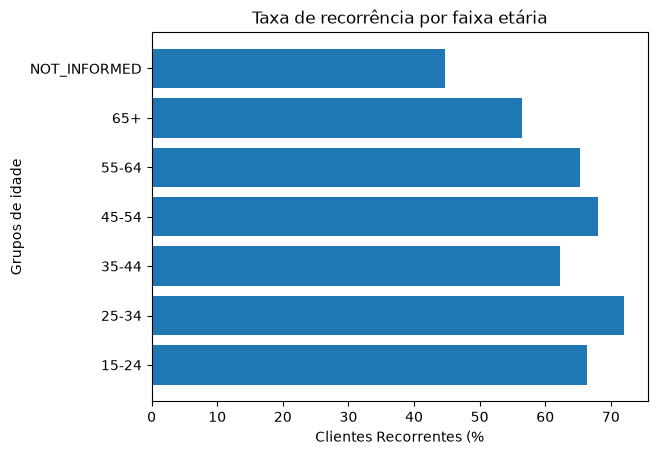

In [14]:
plt.barh(age_analysis["age_group"].astype(str),age_analysis["recurrence_rate"] )
plt.title("Taxa de recorrência por faixa etária")
plt.xlabel("Clientes Recorrentes (%")
plt.ylabel("Grupos de idade")


In [15]:
## Hipótese 2 - Status de Club

club_analysis = customer_purchase.groupby("club_member_status", dropna=False).agg(
    customers = ("customer_id", "nunique"),
    recurrence_rate = ("is_recurring_observed", "mean"),
    avg_purchase_days=("purchase_days", "mean"),
    avg_items=("items_purchased","mean"),
    avg_value=("value","mean")
).reset_index()

club_analysis["recurrence_rate"] *=100
club_analysis["customer_share (%)"] = (club_analysis["customers"] / club_analysis["customers"].sum()) * 100
club_analysis["club_member_status"] = club_analysis["club_member_status"].fillna("Sem Status")


club_analysis

,club_member_status,customers,recurrence_rate,avg_purchase_days,avg_items,avg_value,customer_share (%)
0,ACTIVE,1263183,69.319,7.029,24.587,0.683,92.726
1,LEFT CLUB,466,58.798,4.897,18.324,0.553,0.034
2,PRE-CREATE,92578,39.418,1.955,7.131,0.216,6.796
3,Sem Status,6054,31.599,2.990,10.268,0.303,0.444


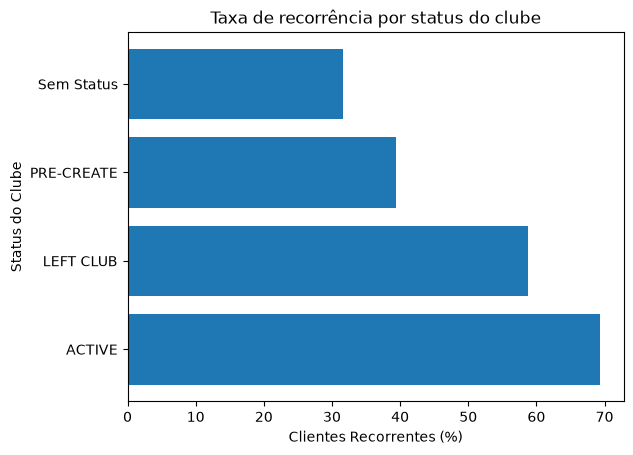

In [16]:
plt.barh(club_analysis["club_member_status"], club_analysis["recurrence_rate"])
plt.title("Taxa de recorrência por status do clube")
plt.xlabel("Clientes Recorrentes (%)")
plt.ylabel("Status do Clube")
plt.show()

In [17]:
## hipótese 3 - Preferência de Canal

channel_analysis = customer_purchase.groupby("channel_profile").agg(
    customers = ("customer_id", "nunique"),
    recurrence_rate = ("is_recurring_observed", "mean"),
    avg_purchase_days=("purchase_days", "mean"),
    avg_items=("items_purchased","mean"),
    avg_value=("value","mean")
).reset_index()

channel_analysis["recurrence_rate"] *=100
channel_analysis["customer_share (%)"] = (channel_analysis["customers"] / channel_analysis["customers"].sum()) * 100

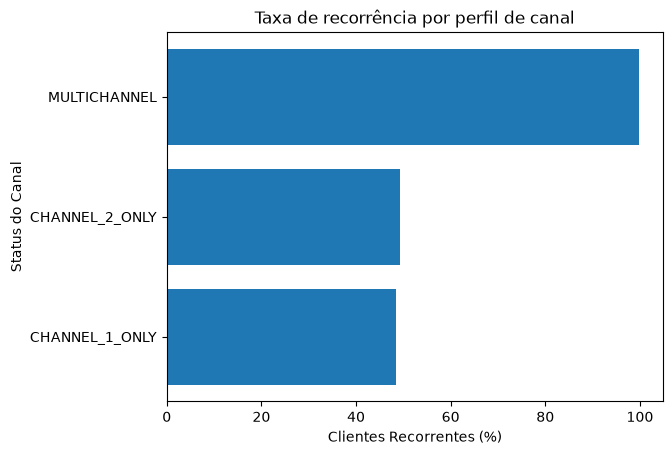

In [18]:
plt.barh(channel_analysis["channel_profile"], channel_analysis["recurrence_rate"])
plt.title("Taxa de recorrência por perfil de canal")
plt.xlabel("Clientes Recorrentes (%)")
plt.ylabel("Status do Canal")
plt.show()

In [19]:
cohort_activity = (
    customer_monthly
    .groupby(["cohort_month", "cohort_index"], as_index=False)
    .agg(active_customers=("customer_id", "nunique"))
)

cohort_size = (
    cohort_activity[cohort_activity["cohort_index"] == 0]
    [["cohort_month", "active_customers"]]
    .rename(columns={"active_customers": "cohort_customers"})
)

cohort_retention = cohort_activity.merge(
    cohort_size,
    on="cohort_month",
    how="left",
)

cohort_retention["retention_rate"] = (
    cohort_retention["active_customers"]
    / cohort_retention["cohort_customers"]
    * 100
)

cohort_retention

,cohort_month,cohort_index,active_customers,cohort_customers,retention_rate
0,2018-09-01,0,140340,140340,100.000
1,2018-09-01,1,61551,140340,43.858
2,2018-09-01,2,59793,140340,42.606
3,2018-09-01,3,56736,140340,40.428
4,2018-09-01,4,53683,140340,38.252
...,...,...,...,...,...
320,2020-07-01,1,3198,23563,13.572
321,2020-07-01,2,1951,23563,8.280
322,2020-08-01,0,22974,22974,100.000
323,2020-08-01,1,2272,22974,9.889


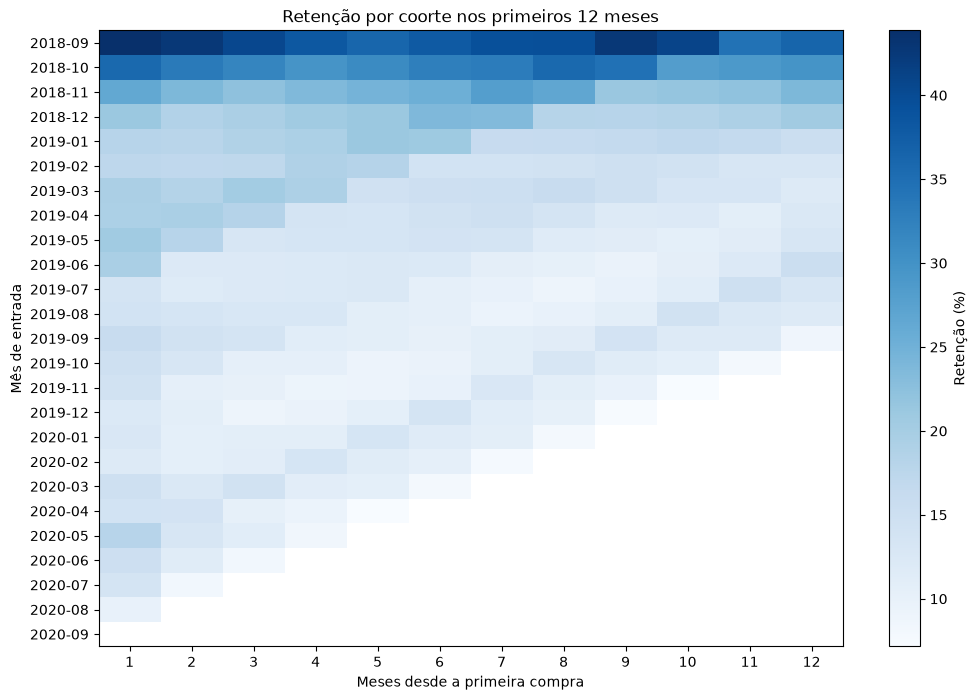

In [20]:
## Análise da retenção por coorte dos 12 meses iniciais

cohort_matrix = (
    cohort_retention
    .pivot(
        index="cohort_month",
        columns="cohort_index",
        values="retention_rate",
    )
    .sort_index()
    .sort_index(axis=1)
)

cohort_matrix = cohort_matrix.drop(columns=0).iloc[:, :12]

fig, ax = plt.subplots(figsize=(12, 8))

heatmap = ax.imshow(
    cohort_matrix,
    aspect="auto",
    cmap="Blues",
)

ax.set_xticks(range(len(cohort_matrix.columns)))
ax.set_xticklabels(cohort_matrix.columns)

ax.set_yticks(range(len(cohort_matrix.index)))
ax.set_yticklabels(cohort_matrix.index.strftime("%Y-%m"))

ax.set_title("Retenção por coorte nos primeiros 12 meses")
ax.set_xlabel("Meses desde a primeira compra")
ax.set_ylabel("Mês de entrada")

fig.colorbar(heatmap, ax=ax, label="Retenção (%)")
plt.show()

### Principais insights

- A faixa de 25 a 34 anos apresentou a maior taxa de recorrência, com 72%, além das maiores médias de itens e valor observado. Essa também é a faixa com maior participação na base, representando 28,7% dos clientes
- Por outro lado, os clientes com 65 anos ou mais apresentaram a menor recorrência dentre as idades informadas, de 56,4%
- Os membros ativos do clube representam 92,7% da base e apresentaram recorrência de 69,3%
- Os clientes multicanal apresentaram frequência, quantidade de itens e valor superiores aos clientes que utilizaram apenas um canal
- A análise por coortes mostra uma redução mais intensa da retenção nos primeiros meses, seguida de maior estabilidade. A primeira coorte apresenta resultados consideravelmente superiores às demais, mas pode incluir clientes que já compravam antes do início da base
- Apesar das descrições que ajudam a entender melhor as características dos clientes recorrentes, não é possível concluir que a idade, participação no clube ou uso de múltiplos canais impliquem na causalidade da recorrência

## 4. Quais grupos de produtos aparecem na primeira compra e nas compras posteriores?


In [21]:
articles_product = pd.read_parquet(DATA_DIR / "articles_clean.parquet",columns=["article_id", "product_group_name"])

In [22]:
## Merge das transações com as bases de produtos

items_stage = transactions_features.groupby(["purchase_stage","article_id"],observed=True).size().reset_index(name="items")

items_stage = items_stage.merge(articles_product,on="article_id", how="left", validate="many_to_one")

###validação
print(items_stage["items"].sum() == len(transactions_features))


display(items_stage.head())


True


,purchase_stage,article_id,items,product_group_name
0,FIRST_OBSERVED_DATE,108775015,3875,Garment Upper body
1,FIRST_OBSERVED_DATE,108775044,1951,Garment Upper body
2,FIRST_OBSERVED_DATE,108775051,149,Garment Upper body
3,FIRST_OBSERVED_DATE,110065001,312,Underwear
4,FIRST_OBSERVED_DATE,110065002,142,Underwear


In [23]:
## Análise da  participação de cada grupo de items na primeira compra e nas posteriores

product_stage_analysis = items_stage.groupby(["purchase_stage", "product_group_name"], observed=True).agg(
    items = ("items", "sum")
).reset_index()

product_stage_analysis

,purchase_stage,product_group_name,items
0,FIRST_OBSERVED_DATE,Accessories,237032
1,FIRST_OBSERVED_DATE,Bags,767
2,FIRST_OBSERVED_DATE,Cosmetic,561
3,FIRST_OBSERVED_DATE,Furniture,57
4,FIRST_OBSERVED_DATE,Garment Full body,444999
5,FIRST_OBSERVED_DATE,Garment Lower body,1094359
6,FIRST_OBSERVED_DATE,Garment Upper body,2101877
7,FIRST_OBSERVED_DATE,Garment and Shoe care,11
8,FIRST_OBSERVED_DATE,Interior textile,15
9,FIRST_OBSERVED_DATE,Items,531


In [24]:
product_stage_analysis["item_share"] = product_stage_analysis["items"]/product_stage_analysis.groupby("purchase_stage")["items"].transform("sum")* 100


product_stage_analysis

,purchase_stage,product_group_name,items,item_share
0,FIRST_OBSERVED_DATE,Accessories,237032,4.783
1,FIRST_OBSERVED_DATE,Bags,767,0.015
2,FIRST_OBSERVED_DATE,Cosmetic,561,0.011
3,FIRST_OBSERVED_DATE,Furniture,57,0.001
4,FIRST_OBSERVED_DATE,Garment Full body,444999,8.980
5,FIRST_OBSERVED_DATE,Garment Lower body,1094359,22.083
6,FIRST_OBSERVED_DATE,Garment Upper body,2101877,42.414
7,FIRST_OBSERVED_DATE,Garment and Shoe care,11,0.000
8,FIRST_OBSERVED_DATE,Interior textile,15,0.000
9,FIRST_OBSERVED_DATE,Items,531,0.011


In [25]:
## Comparação lado a lado por grupos de produto
product_comparison = (
    product_stage_analysis
    .pivot(
        index="product_group_name",
        columns="purchase_stage",
        values="item_share",
    )
    .rename(columns={
        "FIRST_OBSERVED_DATE": "Primeira compra",
        "SUBSEQUENT_DATE": "Compras posteriores",
    })
)

product_comparison["Diferença Percentual"] = (
    product_comparison["Compras posteriores"]
    - product_comparison["Primeira compra"]
)

product_comparison = product_comparison.sort_values(
    "Primeira compra",
    ascending=False,
)

display(product_comparison.round(3))


purchase_stage,Primeira compra,Compras posteriores,Diferença Percentual
product_group_name,,,
Garment Upper body,42.414,38.948,-3.465
Garment Lower body,22.083,22.181,0.098
Garment Full body,8.980,11.581,2.601
Underwear,7.943,8.095,0.152
Swimwear,7.650,8.199,0.549
Accessories,4.783,5.078,0.295
Socks & Tights,2.504,2.093,-0.411
Shoes,2.192,2.374,0.181
Nightwear,1.211,1.074,-0.137


### Principais Insights

- A participação dos grupos de produtos permaneceu com quantidades estáveis em  entre a primeira compra observada e as compras posteriores
- Garment Upper body continuou sendo o principal grupo, mas sua participação caiu de 42,4% para 38,9%, uma redução de 3,5%. Enquanto Garment Full body apresentou o maior crescimento, passando de 9% para 11,6%
- Os demais grupos apresentaram mudanças pequenas, em sua maioria inferiores a 0,5%
- Não foram encontradas evidências de uma mudança ampla no perfil de produtos após a entrada do cliente. As diferenças estão concentradas principalmente na redução de peças para a parte superior e no aumento de peças de corpo inteiro

## 5. Como os canais se relacionam com recorrência, frequência, valor e produtos?


In [26]:
items_channel = transactions_features.groupby(["sales_channel_id", "article_id"],observed=True).size().reset_index(name="items")
items_channel

,sales_channel_id,article_id,items
0,1,108775015,2485
1,1,108775044,2101
2,1,108775051,1
3,1,110065001,652
4,1,110065002,186
...,...,...,...
171645,2,952267001,16
171646,2,952938001,9
171647,2,953450001,17
171648,2,953763001,35


In [27]:
## Merge de transações e produtos

items_channel = items_channel.merge(
    articles_product,on="article_id",how="left", validate="many_to_one"
)

print(items_channel["items"].sum() == len(transactions_features))
display(items_channel)

True


,sales_channel_id,article_id,items,product_group_name
0,1,108775015,2485,Garment Upper body
1,1,108775044,2101,Garment Upper body
2,1,108775051,1,Garment Upper body
3,1,110065001,652,Underwear
4,1,110065002,186,Underwear
...,...,...,...,...
171645,2,952267001,16,Socks & Tights
171646,2,952938001,9,Garment Upper body
171647,2,953450001,17,Socks & Tights
171648,2,953763001,35,Garment Upper body


In [28]:
channel_product_analysis = items_channel.groupby(["sales_channel_id", "product_group_name"],observed=True).agg(
    items=("items", "sum")).reset_index()

channel_product_analysis["item_share"] = channel_product_analysis["items"]/ channel_product_analysis.groupby("sales_channel_id")["items"].transform("sum")*100



In [29]:
## Avaliação da participação de cada canal nos grupos de items
channel_product_comparison = channel_product_analysis.pivot(
        index="product_group_name",
        columns="sales_channel_id",
        values="item_share",
    ).fillna(0)


channel_product_comparison = channel_product_comparison.rename(columns={
    1:"Canal 1",
    2:"Canal 2"
})

channel_product_comparison["Diferença Percentual"] = channel_product_comparison["Canal 2"] - channel_product_comparison["Canal 1"]

channel_product_comparison


sales_channel_id,Canal 1,Canal 2,Diferença Percentual
product_group_name,,,
Accessories,8.654,3.509,-5.145
Bags,0.017,0.026,0.009
Cosmetic,0.011,0.002,-0.008
Fun,0.000,0.000,0.000
Furniture,0.000,0.002,0.002
Garment Full body,7.479,12.729,5.251
Garment Lower body,19.011,23.492,4.481
Garment Upper body,43.821,37.667,-6.154
Garment and Shoe care,0.000,0.001,0.001



### Principais insights

- Entre os clientes que utilizaram somente um canal, as taxas de recorrência foram semelhantes: 48,5% no canal 1 e 49,4% no canal 2
- Os clientes exclusivos do canal 2 apresentaram maior quantidade média de itens e maior valor observado que os clientes exclusivos do canal 1
- Os clientes multicanal representaram 35,5% da base e apresentaram as maiores médias de dias de compra, itens e valor
- O canal 1 apresentou maior participação de Garment Upper body, Accessories, Socks & Tights e Underwear
- O canal 2 apresentou maior participação de Swimwear, Garment Full body, Garment Lower body e Shoes



# Análises Finais

A análise mostra que a recorrência tem papel central no desempenho observado. Embora os recorrentes representem cerca de dois terços dos clientes, eles concentram aproximadamente 95% dos itens e do valor registrado.

O comportamento de retorno é bastante heterogêneo. Metade dos clientes recorrentes voltou em até 44 dias, mas o intervalo entre o primeiro e o terceiro quartil foi de 13 a 120 dias, indicando que, talvez, uma única janela de comunicação pode não ser adequada para todos os clientes.

As características cadastrais apresentaram associações com recorrência e intensidade de compra. A faixa de 25 a 34 anos e os membros ativos do clube tiveram os maiores indicadores

A retenção cai principalmente nos primeiros meses após a entrada.

O mix entre a primeira compra e as posteriores apresentou poucas mudanças. Em contrapartida, foram encontradas diferenças mais claras entre os canais, sugerindo que o canal comercial está mais associado à composição da compra do que a etapa da jornada observada

# Limitações e Premissas


- A primeira compra representa a primeira ocorrência disponível, não necessariamente a primeira compra histórica do cliente.

- As últimas coortes possuem menor tempo de acompanhamento.

- A variável price é normalizada e não deve ser interpretada como receita monetária.

- Os registros representam itens comprados, e não pedidos identificados.

- O significado comercial dos canais 1 e 2 não foi disponibilizado.

- O perfil multicanal é construído com o histórico completo e possui associação parcialmente mecânica com a recorrência.

- As análises são observacionais e não permitem estabelecer causalidade.